# Clasificador de huella de minería ilegal (vista aérea)
Clases: `pozas_mineras`, `monticulos_cascajo`, `suelo_removido`

Datos: parches de dron del dataset **ELDOR** (minería aurífera ilegal en la Amazonía peruana), repositorio `IRSC/ELDOR-sample` en Hugging Face.

Antes de empezar: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU**. Ejecuta las celdas en orden.

## 1. Verificar la GPU

In [5]:
!nvidia-smi

import torch
if not torch.cuda.is_available():
    raise SystemExit("No hay GPU activa. Cambia el entorno de ejecución a T4 GPU y vuelve a ejecutar.")
print("GPU activa:", torch.cuda.get_device_name(0))

Fri Oct 16 12:15:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Instalar dependencias

In [6]:
!pip install -q ultralytics huggingface_hub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 9.7 MB/s eta 0:00:00


## 3. Descargar los parches de ELDOR (~1.4 GB)
Solo se bajan las carpetas `patches/images` y `patches/labels`.

In [7]:
from pathlib import Path
from huggingface_hub import snapshot_download

REPO_HF = "IRSC/ELDOR-sample"

RAIZ = Path(snapshot_download(
    repo_id=REPO_HF,
    repo_type="dataset",
    allow_patterns=["patches/images/*", "patches/labels/*"],
    local_dir="/content/eldor",
))
DIR_IMAGES = RAIZ / "patches" / "images"
DIR_LABELS = RAIZ / "patches" / "labels"
print("Imágenes:", len(list(DIR_IMAGES.glob('*.jpg'))))
print("Etiquetas:", len(list(DIR_LABELS.glob('*.png'))))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19698 files:   0%|          | 0/19698 [00:00<?, ?it/s]

Imágenes: 9849
Etiquetas: 9849


## 4. Armar las tres clases a partir de las etiquetas
Cada parche se asigna a la clase que más área ocupa en él (mínimo 30 %).
Se eligen parches que no se superponen entre sí para que validación no repita píxeles de entrenamiento.

In [8]:
import shutil
import numpy as np
from PIL import Image

# Clases del proyecto -> IDs de etiqueta en ELDOR
CLASES = {
    "pozas_mineras":      [5],      # Water bodies (pozas dejadas por la extracción)
    "monticulos_cascajo": [7, 8],   # Compact mounds + Gravel mounds (material removido)
    "suelo_removido":     [12],     # Bare ground (suelo desnudo por la minería)
}
MIN_FRACCION = 0.30     # la clase debe cubrir al menos el 30 % del parche
MAX_POR_CLASE = 150     # tope para que las clases queden equilibradas
MIN_POR_CLASE = 60      # mínimo deseado por clase

COLORES_ELDOR = {  # por si las etiquetas vienen en color y no como IDs
    0: "000000", 1: "8A6A3D", 2: "7BEBFB", 3: "B04C18", 4: "EE92C6", 5: "4F6F6F",
    6: "84D08C", 7: "23F3E3", 8: "585400", 9: "8DB51D", 10: "C2163A", 11: "F77757",
    12: "2CD874", 13: "613991", 14: "969AAE",
}

def leer_etiqueta(ruta):
    lab = np.array(Image.open(ruta))
    if lab.ndim == 3:
        rgb = lab[..., :3].astype(np.int32)
        codigo = (rgb[..., 0] << 16) | (rgb[..., 1] << 8) | rgb[..., 2]
        ids = np.zeros(codigo.shape, dtype=np.uint8)
        for i, hex_ in COLORES_ELDOR.items():
            ids[codigo == int(hex_, 16)] = i
        lab = ids
    return lab

def fila_columna(ruta):
    _, fila, col = ruta.stem.rsplit("_", 2)
    return int(fila), int(col)

# 1. Fracción de cada clase en cada parche
candidatos = {c: [] for c in CLASES}
etiquetas = sorted(DIR_LABELS.glob("*.png"))
for n, ruta_lab in enumerate(etiquetas, 1):
    lab = leer_etiqueta(ruta_lab)
    conteo = np.bincount(lab.ravel(), minlength=15) / lab.size
    fracciones = {c: conteo[ids].sum() for c, ids in CLASES.items()}
    mejor = max(fracciones, key=fracciones.get)
    if fracciones[mejor] >= MIN_FRACCION:
        candidatos[mejor].append((fracciones[mejor], ruta_lab))
    if n % 2000 == 0:
        print(f"  {n}/{len(etiquetas)} etiquetas revisadas")

# 2. Selección sin solapamiento: con stride 256 y parches de 512,
#    dos parches se superponen si sus filas y columnas difieren en 1 o menos
ORIGEN = Path("/content/imagenes")
shutil.rmtree(ORIGEN, ignore_errors=True)

for clase, lista in candidatos.items():
    lista.sort(key=lambda x: x[0], reverse=True)
    elegidos, ocupados = [], set()
    for frac, ruta_lab in lista:
        f, c = fila_columna(ruta_lab)
        if any((f + df, c + dc) in ocupados for df in (-1, 0, 1) for dc in (-1, 0, 1)):
            continue
        elegidos.append(ruta_lab)
        ocupados.add((f, c))
        if len(elegidos) >= MAX_POR_CLASE:
            break

    # Si no alcanza el mínimo, completa con parches solapados
    if len(elegidos) < MIN_POR_CLASE:
        resto = [r for _, r in lista if r not in elegidos]
        faltan = MIN_POR_CLASE - len(elegidos)
        elegidos += resto[:faltan]
        print(f"AVISO: {clase} se completó con parches solapados")

    destino = ORIGEN / clase
    destino.mkdir(parents=True, exist_ok=True)
    for ruta_lab in elegidos:
        img = DIR_IMAGES / (ruta_lab.stem + ".jpg")
        shutil.copy(img, destino / img.name)
    print(f"{clase}: {len(elegidos)} imágenes (candidatos: {len(lista)})")

  2000/9849 etiquetas revisadas
  4000/9849 etiquetas revisadas
  6000/9849 etiquetas revisadas
  8000/9849 etiquetas revisadas
pozas_mineras: 150 imágenes (candidatos: 775)
AVISO: monticulos_cascajo se completó con parches solapados
monticulos_cascajo: 60 imágenes (candidatos: 62)
suelo_removido: 150 imágenes (candidatos: 1683)


## 5. Ver ejemplos de cada clase

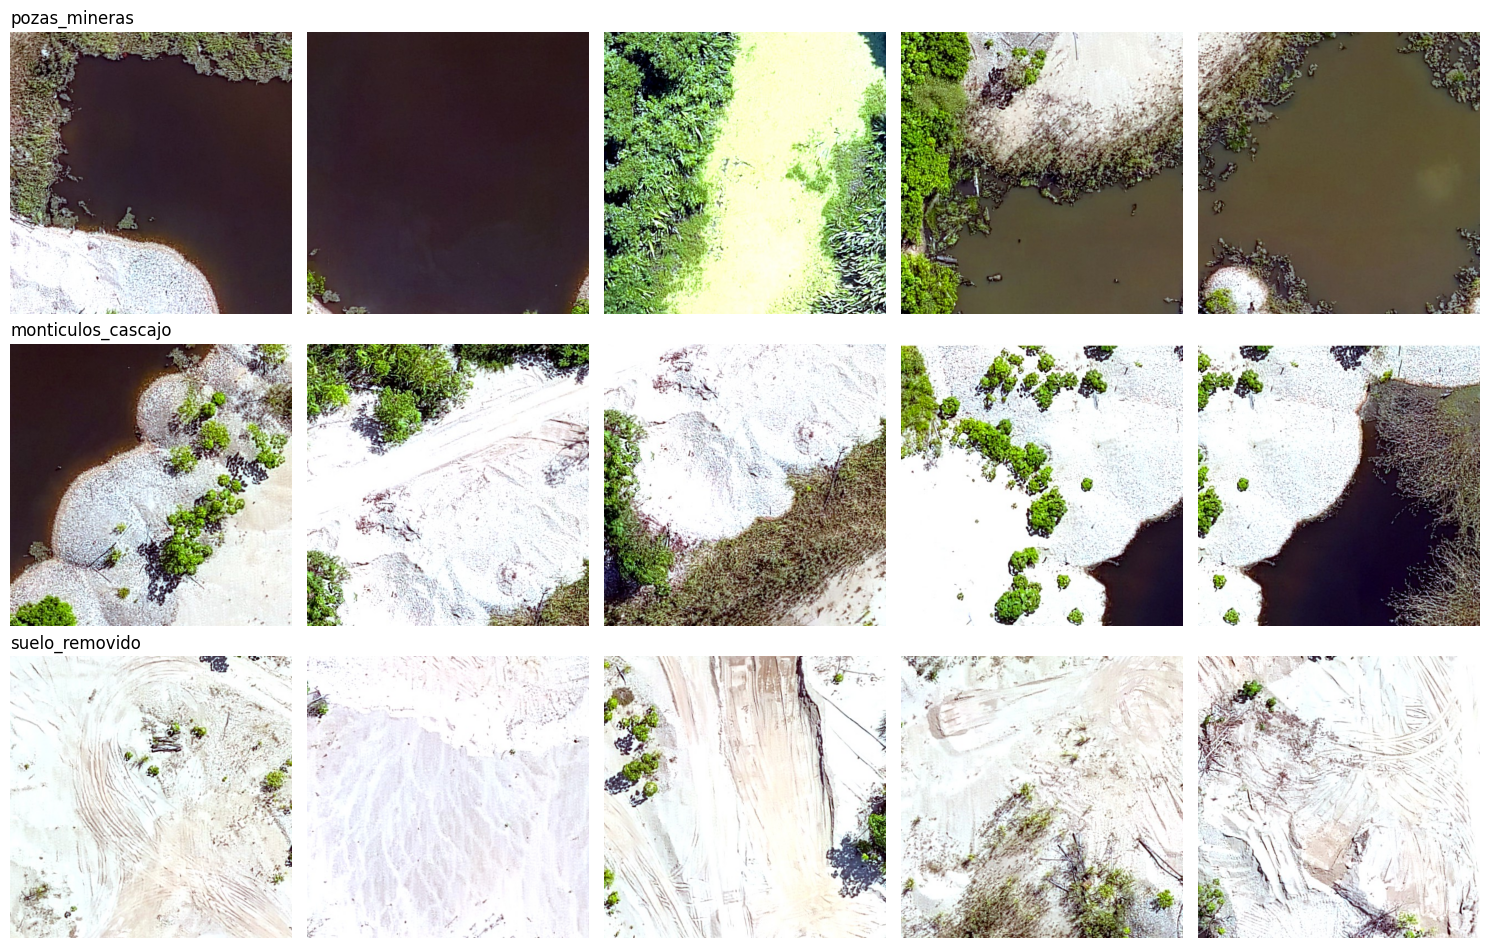

In [9]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(len(CLASES), 5, figsize=(15, 3.2 * len(CLASES)))
for fila, clase in enumerate(CLASES):
    fotos = sorted((ORIGEN / clase).glob("*.jpg"))[:5]
    for col, eje in enumerate(ejes[fila]):
        eje.axis("off")
        if col < len(fotos):
            eje.imshow(Image.open(fotos[col]))
        if col == 0:
            eje.set_title(clase, loc="left", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Separar entrenamiento (80 %) y validación (20 %)

In [10]:
import random

DATASET = Path("/content/dataset")
random.seed(42)
shutil.rmtree(DATASET, ignore_errors=True)

for clase in CLASES:
    fotos = sorted((ORIGEN / clase).glob("*.jpg"))
    random.shuffle(fotos)
    n_val = max(1, int(len(fotos) * 0.2))
    for i, foto in enumerate(fotos):
        subset = "val" if i < n_val else "train"
        destino = DATASET / subset / clase
        destino.mkdir(parents=True, exist_ok=True)
        shutil.copy(foto, destino / foto.name)
    print(f"{clase}: {len(fotos) - n_val} train, {n_val} val")

pozas_mineras: 120 train, 30 val
monticulos_cascajo: 48 train, 12 val
suelo_removido: 120 train, 30 val


## 7. Entrenar por línea de comandos (100 épocas en GPU)
`device=0` obliga a usar la T4.

In [11]:
!yolo classify train data=/content/dataset model=yolo11n-cls.pt epochs=100 imgsz=320 batch=32 device=0 project=/content/mineria name=modelo_v1 exist_ok=True

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None,

## 8. Evaluar el modelo

In [12]:
!yolo classify val model=/content/mineria/modelo_v1/weights/best.pt data=/content/dataset imgsz=320 device=0

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-cls summary (fused): 47 layers, 1,529,867 parameters, 0 gradients, 3.2 GFLOPs
train: /content/dataset/train... found 288 images in 3 classes ✅ 
val: /content/dataset/val... found 72 images in 3 classes ✅ 
test: None...
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3471.5±858.5 MB/s, size: 99.8 KB)
val: Scanning /content/dataset/val... 72 images, 0 corrupt: 100% ━━━━━━━━━━━━ 72/72 13.7Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 5/5 2.8it/s 1.8s
                   all      0.986          1
Speed: 3.5ms preprocess, 14.2ms inference, 0.1ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
💡 Learn more at https://docs.ultralytics.com/modes/val


results.png


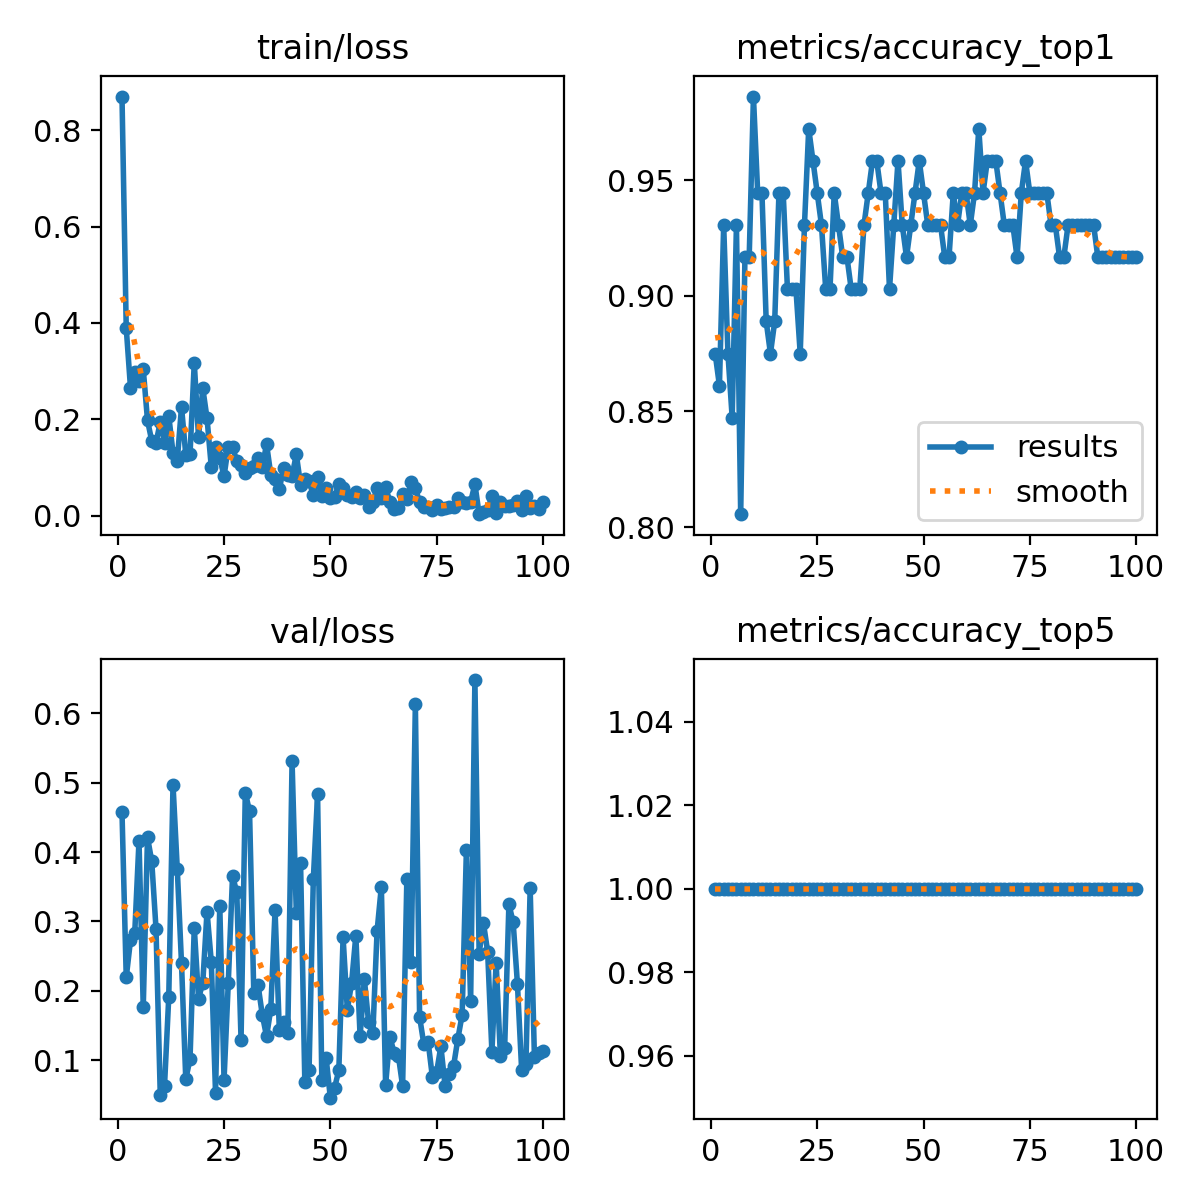

confusion_matrix_normalized.png


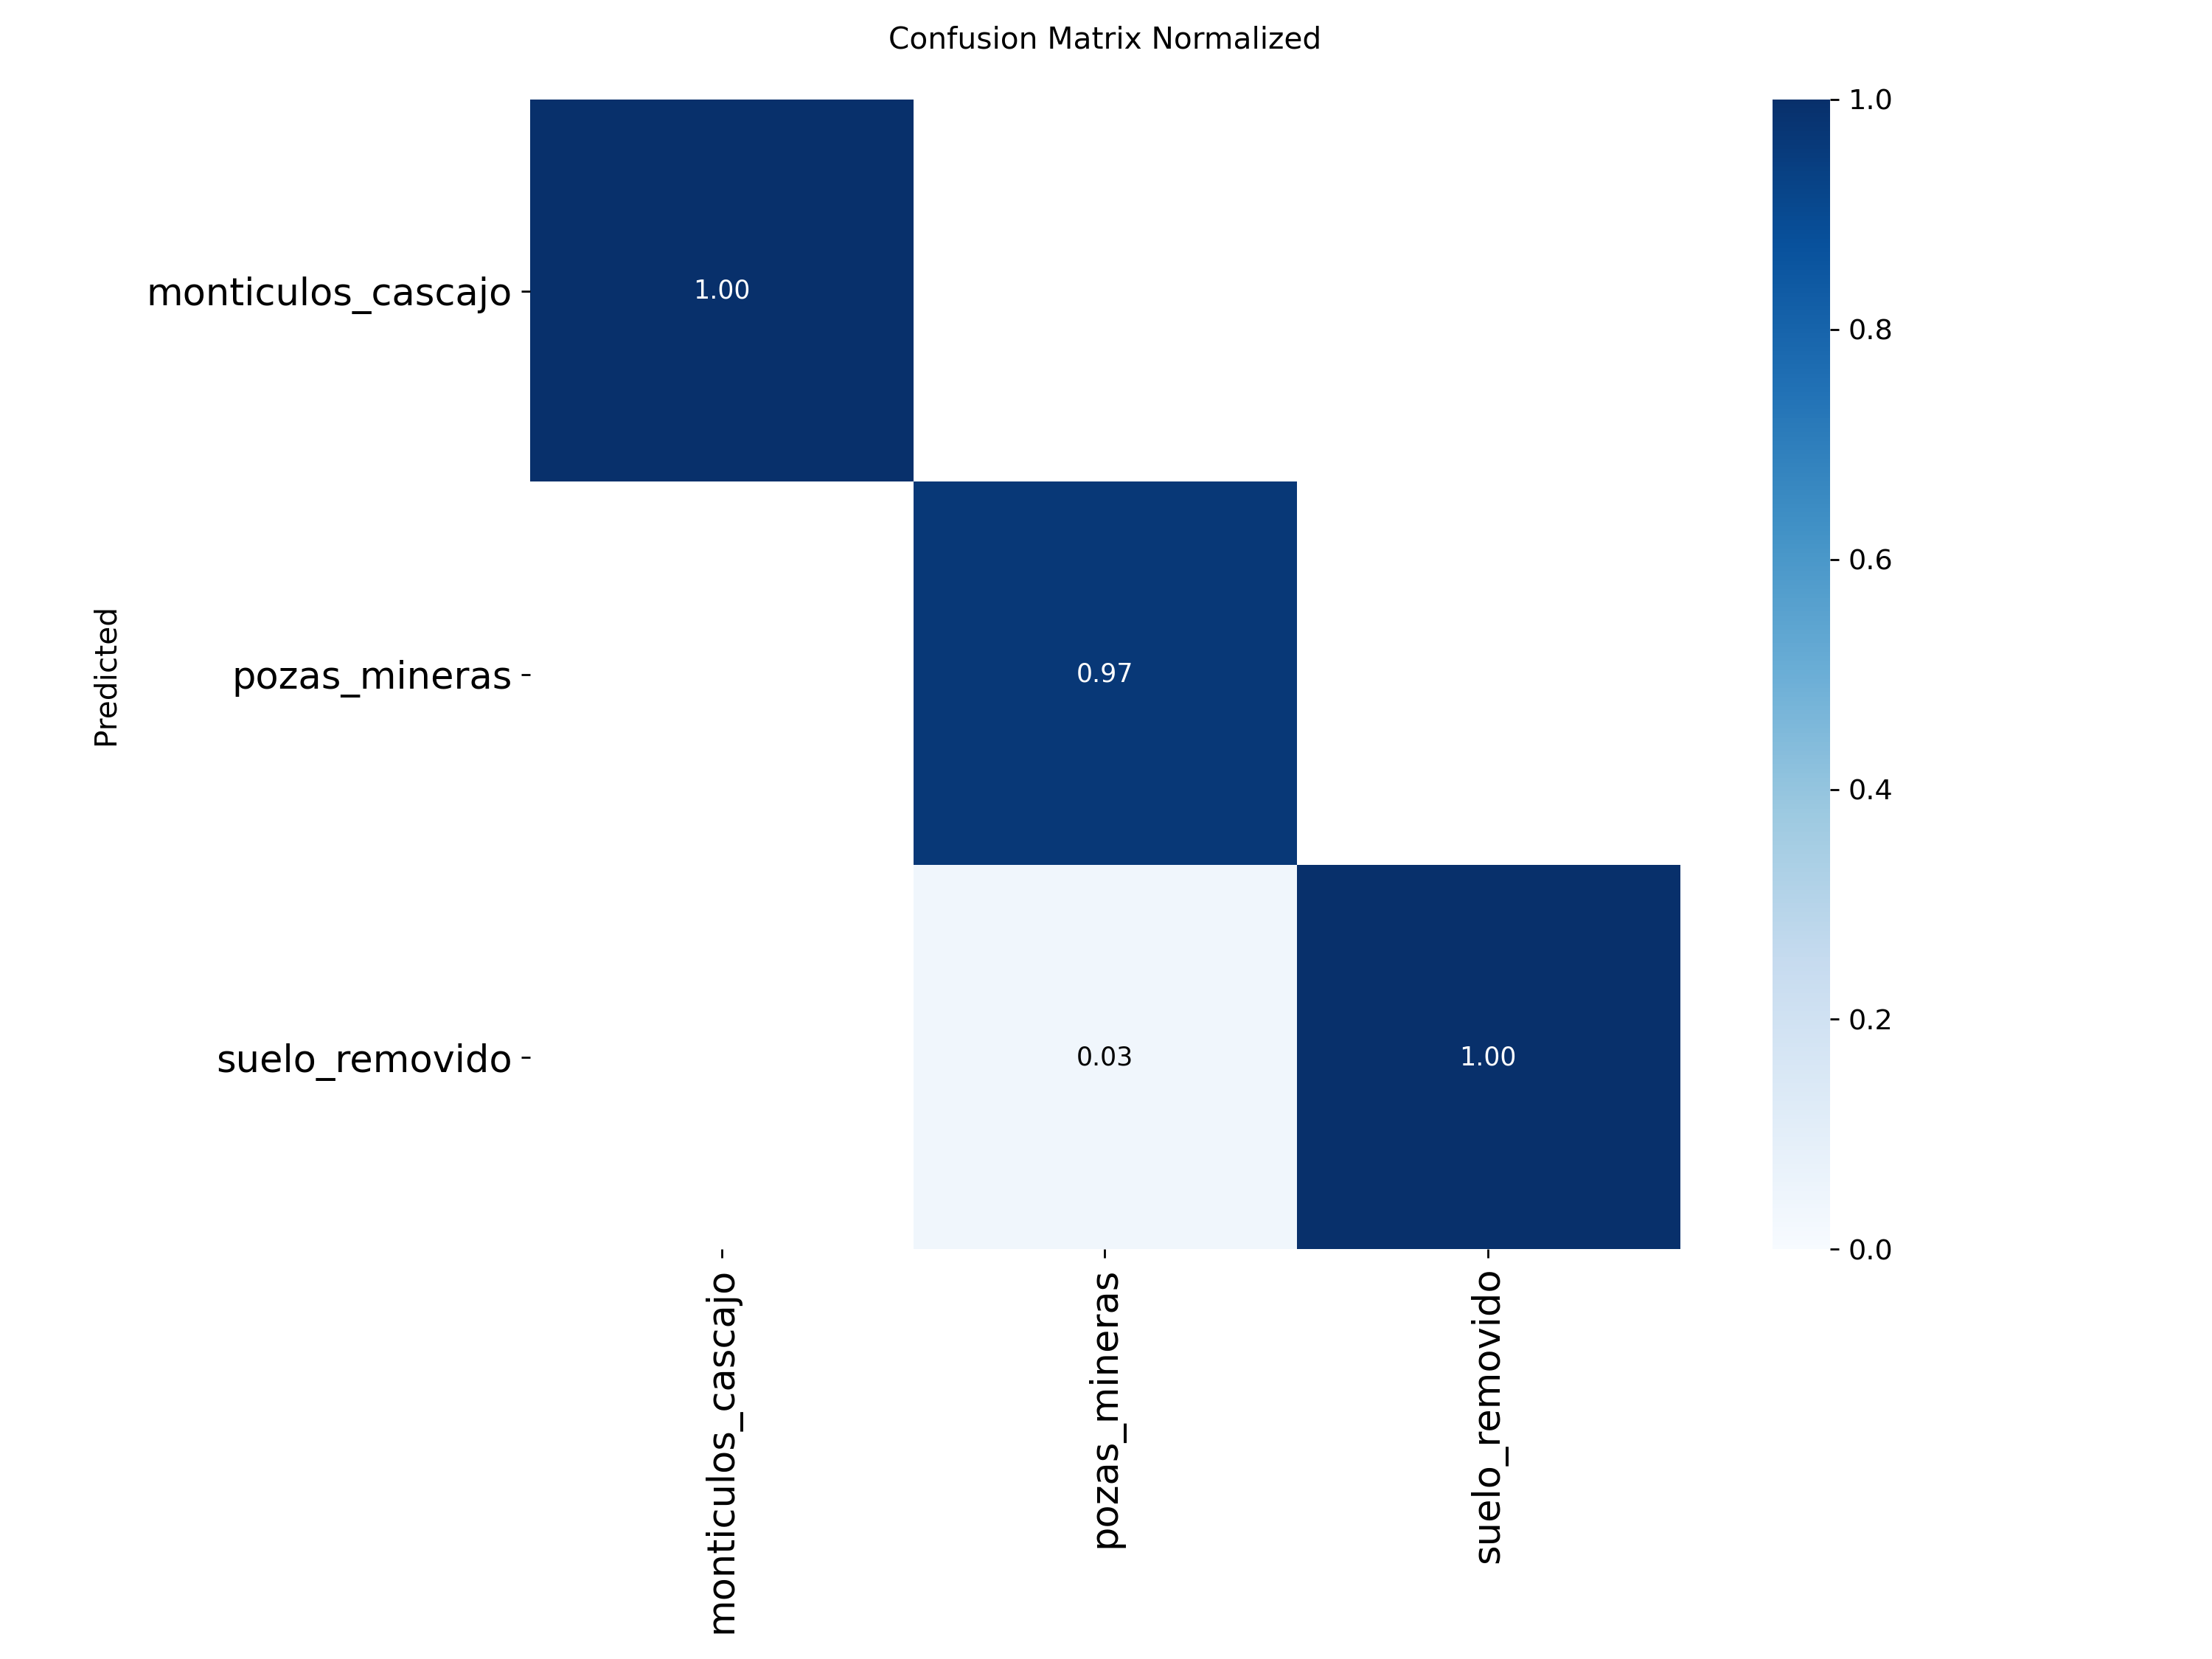

confusion_matrix.png


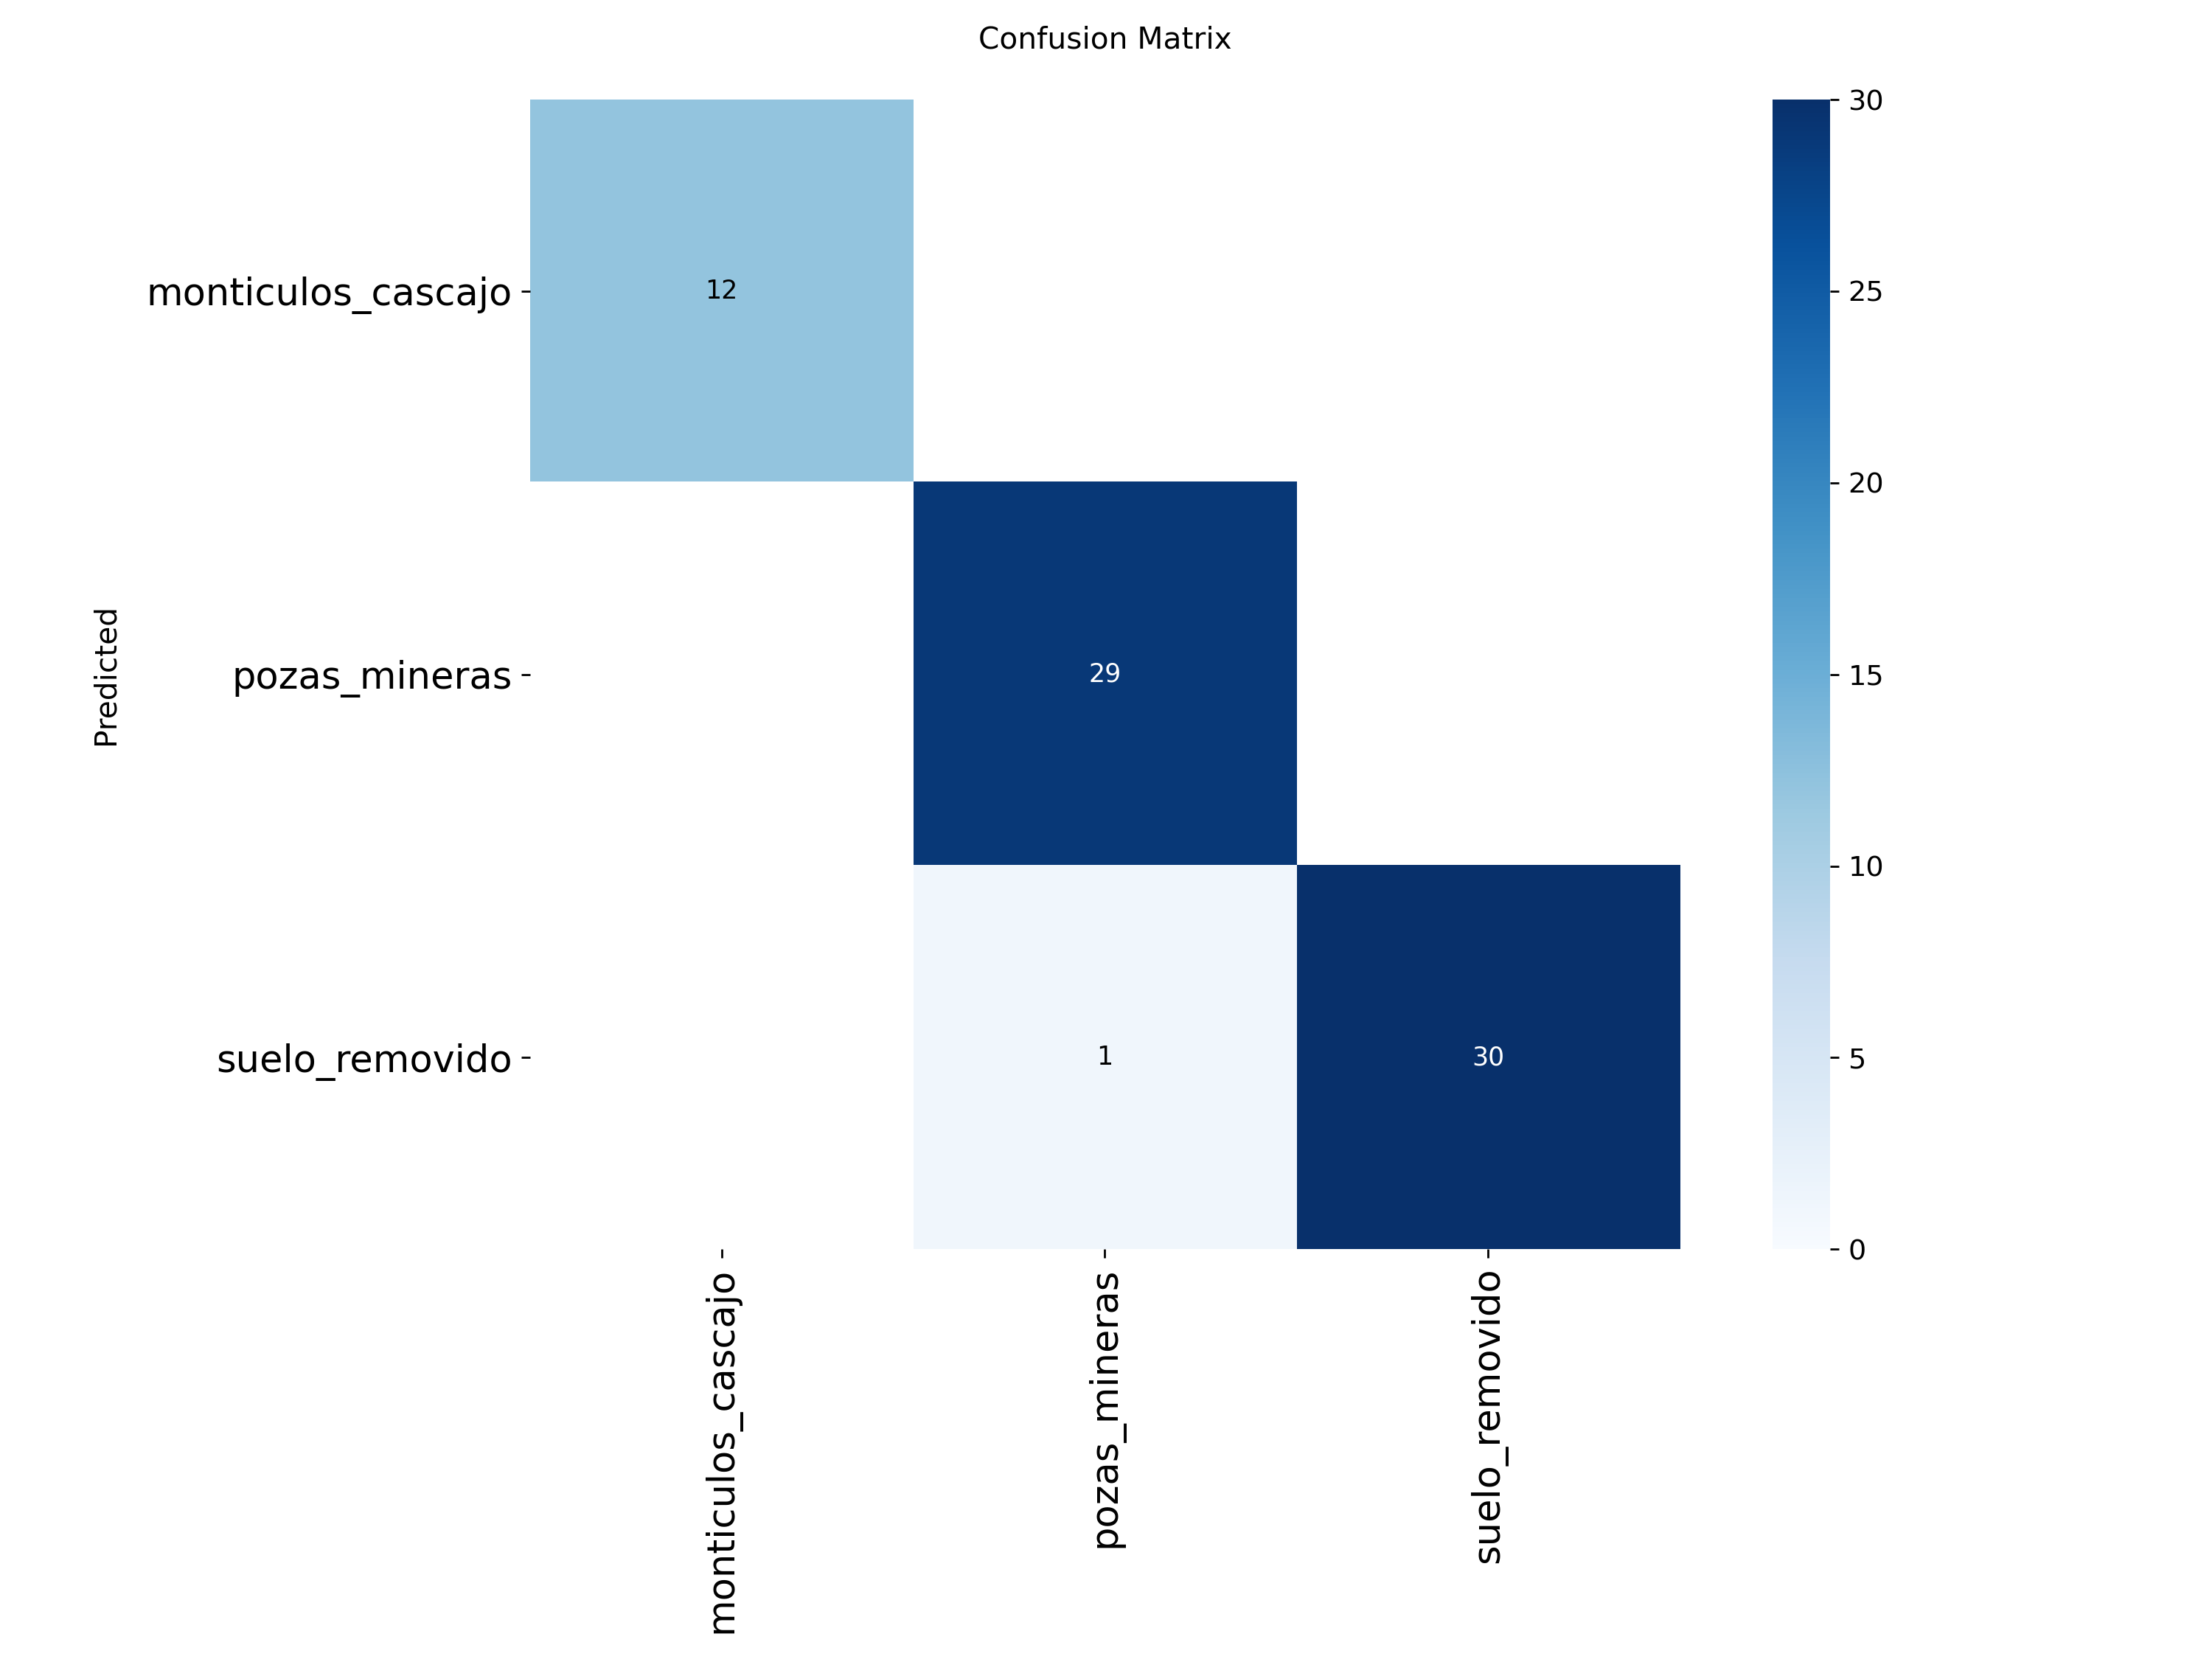

In [13]:
from IPython.display import Image as IPImage, display

CARPETA_MODELO = Path("/content/mineria/modelo_v1")
for nombre in ["results.png", "confusion_matrix_normalized.png", "confusion_matrix.png"]:
    ruta = CARPETA_MODELO / nombre
    if ruta.exists():
        print(nombre)
        display(IPImage(filename=str(ruta), width=700))

## 9. Preparar imágenes de prueba que el modelo nunca vio
Se copian 5 parches por clase que no se usaron en el dataset, para probar `inferencia.py` en tu computadora.

In [14]:
usados = {f.name for f in DATASET.rglob("*.jpg")}
PRUEBA = Path("/content/imagenes_prueba")
shutil.rmtree(PRUEBA, ignore_errors=True)
PRUEBA.mkdir()

for clase, lista in candidatos.items():
    extra = [r for _, r in lista if (r.stem + ".jpg") not in usados][:5]
    for ruta_lab in extra:
        img = DIR_IMAGES / (ruta_lab.stem + ".jpg")
        shutil.copy(img, PRUEBA / f"{clase}__{img.name}")
    print(f"{clase}: {len(extra)} imágenes de prueba")

pozas_mineras: 5 imágenes de prueba
monticulos_cascajo: 2 imágenes de prueba
suelo_removido: 5 imágenes de prueba


## 10. Descargar modelo e imágenes de prueba

In [15]:
shutil.copytree(PRUEBA, CARPETA_MODELO / "imagenes_prueba", dirs_exist_ok=True)
ZIP_SALIDA = shutil.make_archive("/content/modelo_mineria", "zip", root_dir="/content/mineria", base_dir="modelo_v1")

from google.colab import files
files.download(ZIP_SALIDA)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Interfaz interactiva con Gradio
Instalamos `gradio` y creamos una aplicación web interactiva para probar el modelo clasificador con nuevas imágenes.

In [16]:
!pip install -q gradio

In [17]:
import gradio as gr
from ultralytics import YOLO
from PIL import Image

# Cargar el modelo entrenado
ruta_modelo = "/content/mineria/modelo_v1/weights/best.pt"
model = YOLO(ruta_modelo)

def clasificar_imagen(imagen_pil):
    if imagen_pil is None:
        return {}

    # Realizar la predicción
    resultados = model.predict(source=imagen_pil, imgsz=320, verbose=False)

    # Extraer las probabilidades
    probs = resultados[0].probs
    nombres_clases = resultados[0].names

    # Mapear cada clase con su confianza
    confianzas = {}
    for i, score in enumerate(probs.data.tolist()):
        clase = nombres_clases[i]
        confianzas[clase] = float(score)

    return confianzas

# Crear la interfaz de Gradio
demo = gr.Interface(
    fn=clasificar_imagen,
    inputs=gr.Image(type="pil", label="Sube una imagen aérea (parche de dron)"),
    outputs=gr.Label(num_top_classes=3, label="Resultados de la clasificación"),
    title="Clasificador de Huella de Minería Ilegal",
    description="Sube un parche de imagen aérea para identificar la firma o huella de minería ilegal (pozas, cascajo o suelo removido).",
    examples=sorted([str(f) for f in Path("/content/imagenes_prueba").glob("*.jpg")])[:6]
)

# Lanzar en Colab con un enlace público temporal opcional
demo.launch(inline=True, share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ecd0c3656b1ef58be5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
